In [1]:
import sys
import mne
import numpy as np
import scipy
import sklearn
import torch
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)

print("\nAll imports successful!")

Python: 3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]
MNE: 1.12.1
NumPy: 2.5.1
SciPy: 1.18.0
Scikit-learn: 1.9.0
PyTorch: 2.14.1+cu126

All imports successful!


In [3]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [7]:
import mne
import numpy as np
import matplotlib.pyplot as plt

file_path = "/home/shivansh/Documents/Programs/Internship_ke_liye_projects/EEG_projects/eeg-motor-imagery/notebooks/archive/files/S001/S001R08.edf"

raw = mne.io.read_raw_edf(file_path, preload = True, verbose = False)

print(raw)
print("\nSampling Frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", len(raw.ch_names))
print("Recording duration:", round(raw.times[-1], 2), "seconds")

print("\nChannel names:")
print(raw.ch_names)

<RawEDF | S001R08.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

Sampling Frequency: 160.0 Hz
Number of channels: 64
Recording duration: 124.99 seconds

Channel names:
['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']


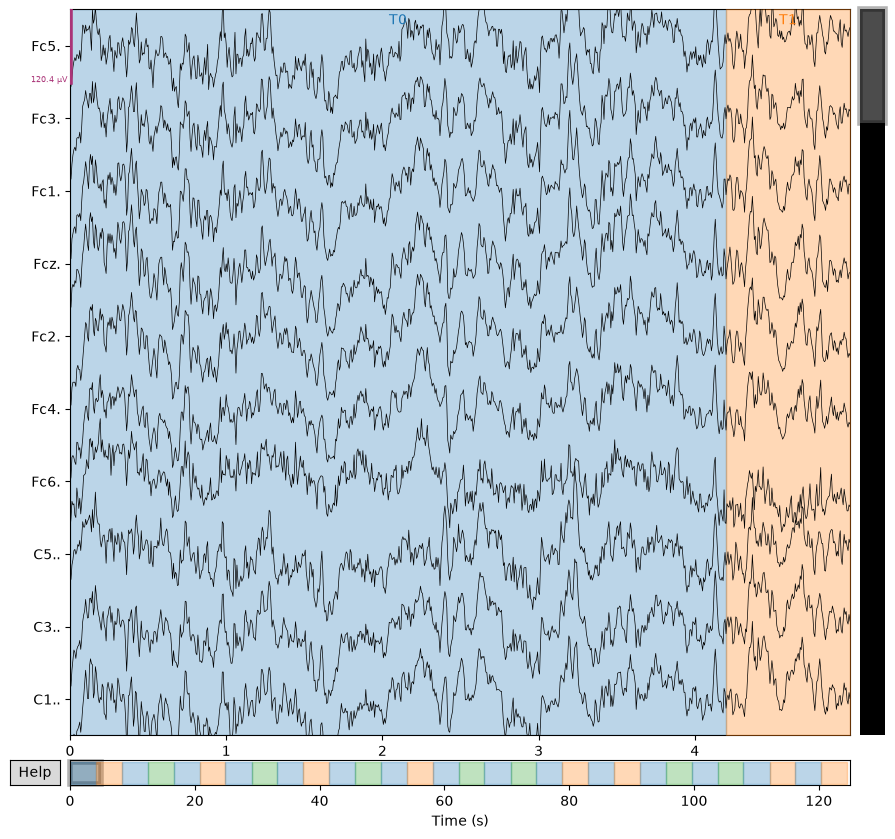

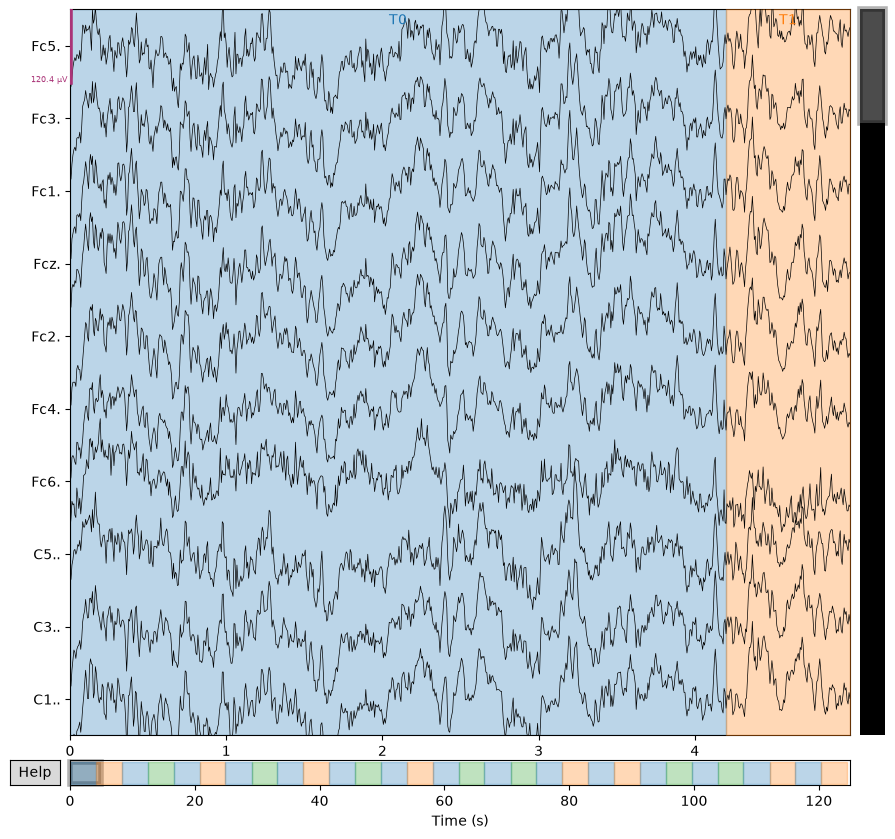

In [8]:
raw.plot(duration = 5, n_channels= 10, scalings = "auto")

In [9]:
print("Annotations:")
print(raw.annotations)

events, event_id = mne.events_from_annotations(raw)

print("\nEvent IDs:")
print(event_id)

print("\nFirst 20 events:")
print(events[:20])

Annotations:
<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>
Used Annotations descriptions: [np.str_('T0'), np.str_('T1'), np.str_('T2')]

Event IDs:
{np.str_('T0'): 1, np.str_('T1'): 2, np.str_('T2'): 3}

First 20 events:
[[    0     0     1]
 [  672     0     2]
 [ 1328     0     1]
 [ 2000     0     3]
 [ 2656     0     1]
 [ 3328     0     2]
 [ 3984     0     1]
 [ 4656     0     3]
 [ 5312     0     1]
 [ 5984     0     2]
 [ 6640     0     1]
 [ 7312     0     3]
 [ 7968     0     1]
 [ 8640     0     2]
 [ 9296     0     1]
 [ 9968     0     3]
 [10624     0     1]
 [11296     0     3]
 [11952     0     1]
 [12624     0     2]]


Number of EEG channels: 64
Sampling frequency: 160.0
Montage assigned successfully!
Number of channels: 64


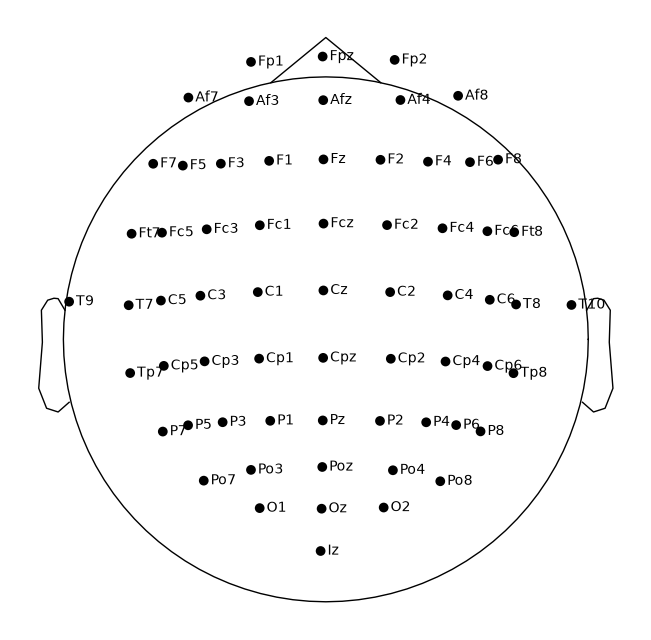

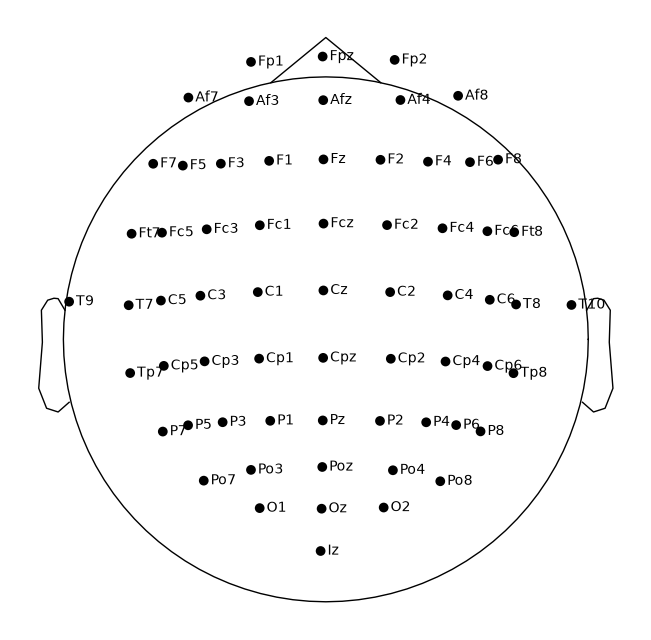

In [23]:
raw_eeg = raw.copy()

print("Number of EEG channels:", len(raw_eeg.ch_names))
print("Sampling frequency:", raw_eeg.info["sfreq"])

rename_dict = {
    ch: ch.rstrip(".")
    for ch in raw_eeg.ch_names
}

raw_eeg.rename_channels(rename_dict)

# Assign standard electrode positions
montage = mne.channels.make_standard_montage("standard_1005")

raw_eeg.set_montage(
    montage,
    match_case=False,
    on_missing="raise"
)

print("Montage assigned successfully!")
print("Number of channels:", len(raw_eeg.ch_names))

# Visualize electrode positions
raw_eeg.plot_sensors(show_names=True)

In [24]:
raw_filtered = raw_eeg.copy()

raw_filtered.filter(
    l_freq=8.0,
    h_freq=30.0,
    picks="eeg",
    method="fir",
    phase="zero",
    verbose=False
)

print("Filtering completed.")

Filtering completed.


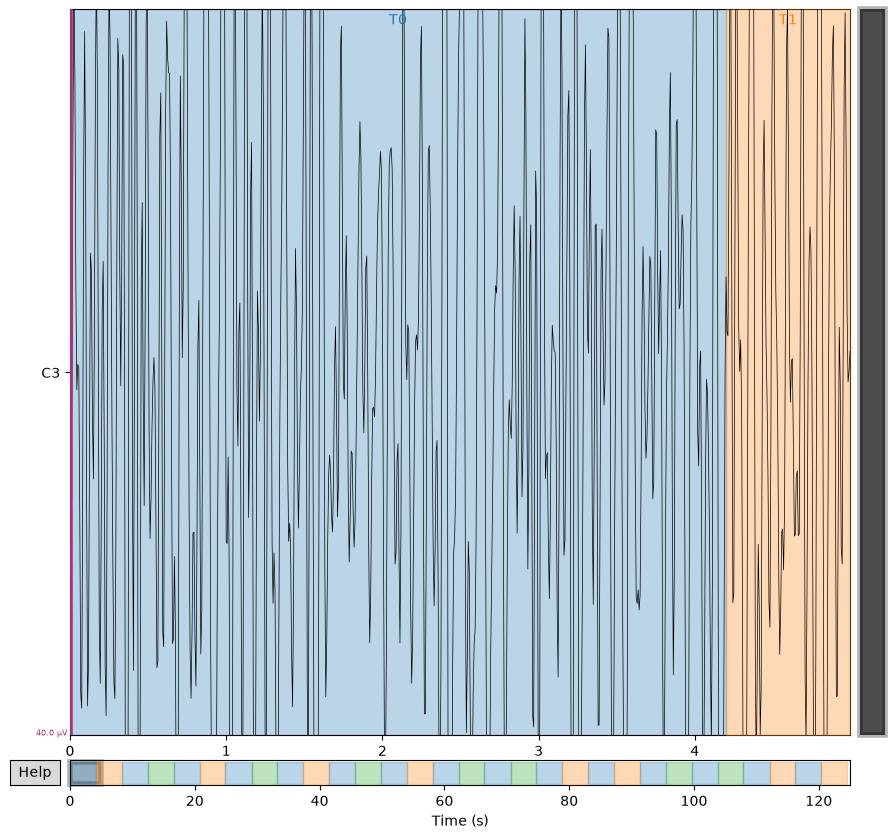

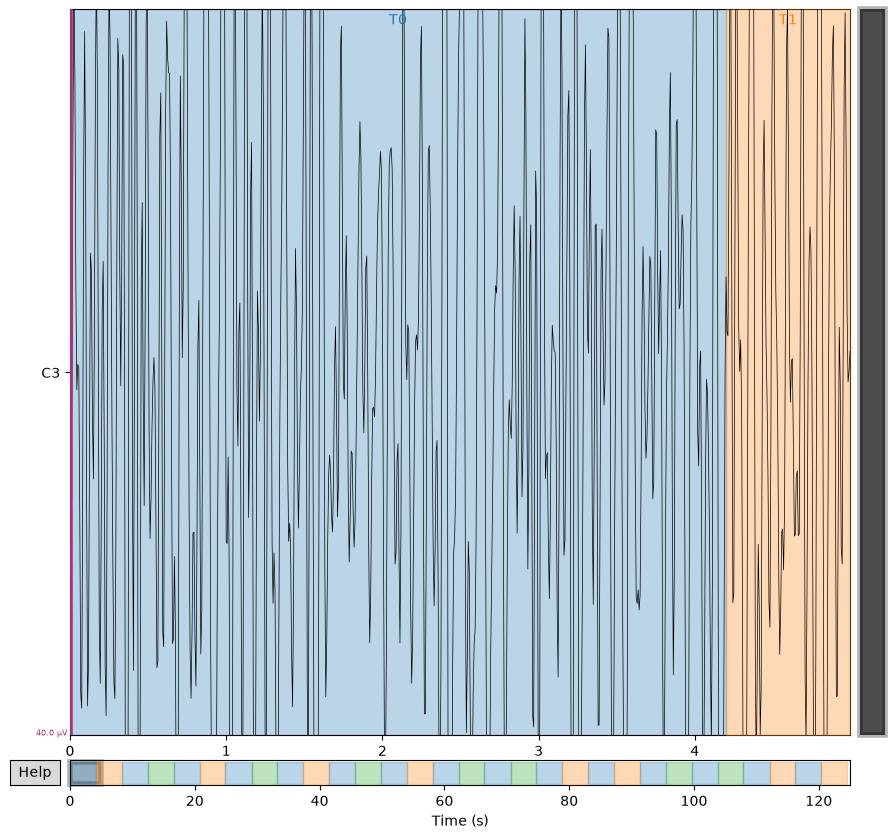

In [25]:
raw_filtered.plot(
    picks=["C3"],
    duration=5
)

In [29]:
import numpy as np
import mne

# Extract events
events, event_id = mne.events_from_annotations(
    raw_filtered,
    verbose=False
)

print("Event mapping:", event_id)

# Select imagined left- and right-hand movements
motor_event_id = {
    "left_hand": event_id["T1"],
    "right_hand": event_id["T2"]
}

# Extract epochs
epochs = mne.Epochs(
    raw_filtered,
    events,
    event_id=motor_event_id,
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    reject_by_annotation=True,
    verbose=False
)

# Extract the EEG data
X = epochs.get_data()

# Create binary labels
event_codes = epochs.events[:, -1]
y = np.where(event_codes == event_id["T1"], 0, 1)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Left-hand trials:", np.sum(y == 0))
print("Right-hand trials:", np.sum(y == 1))

Event mapping: {np.str_('T0'): 1, np.str_('T1'): 2, np.str_('T2'): 3}
Dataset shape: (15, 64, 481)
Labels shape: (15,)
Left-hand trials: 8
Right-hand trials: 7


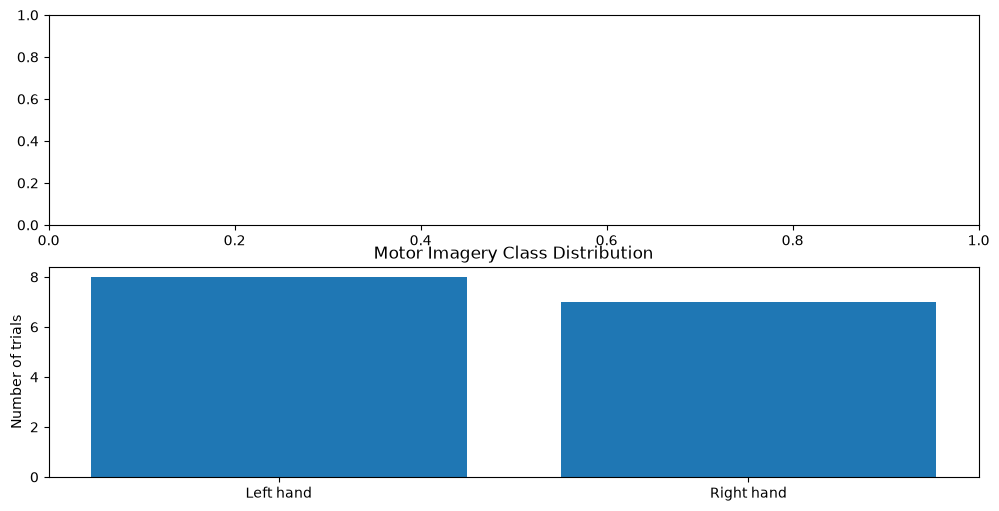

In [30]:
import matplotlib.pyplot as plt

left_count = np.sum(y == 0)
right_count = np.sum(y == 1)

plt.bar(
    ["Left hand", "Right hand"],
    [left_count, right_count]
)

plt.ylabel("Number of trials")
plt.title("Motor Imagery Class Distribution")
plt.show()